# 01 - Network Packet-Level Analysis (V1) - corrected version
**Project:** multimodal intrusion detection in 5G Open RAN - **analysis only** (no cleaning, no model training for the project).

**What changed vs the previous run:** the previous run could not find the dataset, so every analysis cell was skipped and the
"CONFIRMED" findings were hard-coded text. This version (1) **stops with a clear error** if the dataset is not attached,
(2) never prints a finding that was not computed, (3) reads each packet file **once**, in chunks, (4) parses `frame.time` with its
time-zone label, and (5) uses the per-scenario packet CSVs as the source of truth (the `.db` named *Higher_Layer* holds **flows**, not packets).

**Before running (Kaggle):** right sidebar -> *Add Input* -> search `netslab-5g-oran-idd` (user `netslabdemo`) -> add it, then *Run All*.

## 1. Configuration and dataset discovery

In [2]:
import os, re, glob, json, time, sqlite3, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60, "display.width", 250, "display.max_rows", 120, "display.float_format", "{:,.3f}".format)

# ---- knobs ----
CHUNK              = 400_000     # rows per read chunk
MAX_ROWS_PER_FILE  = None        # e.g. 200_000 for a quick test run; None = read every packet
TZ_OFFSETS         = {"GMT": 0, "UTC": 0, "IST": 3600}   # seconds that the label adds to UTC. IST=+1h was what the earlier radio/packet
                                                          # overlap check supported; Indian Standard Time would be +19800 - verify if IST appears.
GAP_SECONDS        = 5           # a silence longer than this inside a capture is reported as a gap
RANDOM_STATE       = 42

def find_base():
    cands = [os.environ.get("NETSLAB_BASE"), "/kaggle/input/datasets/netslabdemo/netslab-5g-oran-idd", "/kaggle/input/netslab-5g-oran-idd"]
    for c in cands:
        if c and os.path.isdir(c): return c
    root0 = "/kaggle/input"
    for root, dirs, _ in os.walk(root0):
        if root.count(os.sep) - root0.count(os.sep) > 4: dirs[:] = []; continue
        if "Attack (Legacy) Version 1" in dirs: return root
    return None

BASE = find_base()
if BASE is None:
    raise FileNotFoundError("Dataset not found under /kaggle/input. Add the Kaggle dataset 'netslabdemo/netslab-5g-oran-idd' as an input "
                            "(right sidebar > Add Input), then Restart & Run All.")
V1  = os.path.join(BASE, "Attack (Legacy) Version 1")
OUT = "/kaggle/working/analysis/network_outputs" if os.path.isdir("/kaggle/working") else "./outputs/network_outputs"
os.makedirs(OUT, exist_ok=True)

# one pass over the V1 folder: filename -> full path (robust to sub-folder naming)
INDEX = {}
for root, _, files in os.walk(V1):
    for f in files: INDEX.setdefault(f, os.path.join(root, f))
print("BASE:", BASE); print("V1 files indexed:", len(INDEX)); print("OUT :", OUT)

BASE: /kaggle/input/datasets/netslabdemo/netslab-5g-oran-idd
V1 files indexed: 220
OUT : /kaggle/working/analysis/network_outputs


## 2. Scenario manifest
Scenario name, attack family, mode (DoS / DDoS / PortScan / Benign) and the binary label are **derived from the filename**, the same way the dataset owners did.
`is_attack` is a separate 0/1 column so it cannot be confused with the owners' `traffic_type` text column.

In [3]:
STEMS = (["filteredBenign%d" % i for i in range(1, 7)] +
         ["filtered%s%d" % (p, i) for p in ["TCP", "DDOSTCP", "SYN", "DDOSSYN"] for i in range(1, 4)] +
         ["filteredUDP%d" % i for i in range(1, 6)] + ["filteredDDOSUDP%d" % i for i in range(1, 4)] +
         ["filtered%s%d" % (p, i) for p in ["ICMP", "DDOSICMP", "PortScan"] for i in range(1, 4)])

def describe(stem):
    sc = stem.replace("filtered", "", 1); low = sc.lower()
    if   "benign"   in low: fam, mode = "Benign", "Benign"
    elif "portscan" in low: fam, mode = "PortScan", "PortScan"
    else:
        fam  = "SYN" if "syn" in low else "TCP" if "tcp" in low else "UDP" if "udp" in low else "ICMP" if "icmp" in low else "Unknown"
        mode = "DDoS" if low.startswith("ddos") else "DoS"
    return dict(stem=stem, scenario=sc, family=fam, mode=mode, is_attack=int(fam != "Benign"))

rows = []
for s in STEMS:
    d = describe(s)
    for key, name in [("pkt", s + ".csv"), ("flow", s + "flow.csv"), ("pcap", s + ".pcap")]:
        p = INDEX.get(name); d[key + "_path"] = p
        d[key + "_mb"] = round(os.path.getsize(p) / 1e6, 1) if p else None
    rows.append(d)
MAN = pd.DataFrame(rows)
print(f"packet CSVs found: {MAN.pkt_path.notna().sum()}/{len(MAN)}   flow CSVs: {MAN.flow_path.notna().sum()}/{len(MAN)}   pcaps: {MAN.pcap_path.notna().sum()}/{len(MAN)}")
display(MAN[["scenario", "family", "mode", "is_attack", "pkt_mb", "flow_mb", "pcap_mb"]])
if MAN.pkt_path.notna().sum() == 0:
    raise FileNotFoundError("No per-scenario packet CSVs (filtered*.csv) found under 'Attack Filtered/Filtered'. Check the input listing.")

packet CSVs found: 35/35   flow CSVs: 35/35   pcaps: 35/35


,scenario,family,mode,is_attack,pkt_mb,flow_mb,pcap_mb
0,Benign1,Benign,Benign,0,1.000,0.000,0.800
1,Benign2,Benign,Benign,0,1.200,0.000,1.000
2,Benign3,Benign,Benign,0,1.400,0.000,1.200
3,Benign4,Benign,Benign,0,67.400,0.000,484.400
4,Benign5,Benign,Benign,0,145.200,0.000,"1,212.300"
5,Benign6,Benign,Benign,0,165.800,0.000,"1,435.600"
6,TCP1,TCP,DoS,1,7.600,0.400,3.900
7,TCP2,TCP,DoS,1,13.700,0.700,7.000
8,TCP3,TCP,DoS,1,23.800,1.300,12.200
9,DDOSTCP1,TCP,DDoS,1,64.400,0.000,31.000


## 3. What do the V1 `.db` files actually contain?
The previous notebook assumed `5G-NL-IDD_Higher_Layer_Network_Data.db` has a 28.8M-row `Network_Data` table. Earlier outputs showed it holds **`Higher_Level_Data` = 204,775 flow rows**.
This cell inspects every `.db` it finds, so the answer is evidence and not an assumption (and it settles whether any packet database with labels is shipped).

In [4]:
dbs = []
for name, path in INDEX.items():
    if not name.lower().endswith(".db"): continue
    con = sqlite3.connect(f"file:{path}?mode=ro", uri=True)
    for t in pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", con).name:
        cols = pd.read_sql(f'PRAGMA table_info("{t}")', con).name.tolist()
        n = pd.read_sql(f'SELECT MAX(rowid) n FROM "{t}"', con).n[0]
        dbs.append({"db": name, "table": t, "rows": int(n) if n == n and n is not None else 0, "n_cols": len(cols),
                    "has_traffic_label": "traffic_label" in cols, "has_traffic_type": "traffic_type" in cols,
                    "has_frame_time": "frame.time" in cols, "kind": "PACKETS" if "frame.time" in cols else "FLOWS" if "orig_pkts" in cols or "src_pkts" in cols else "OTHER/EMPTY"})
    con.close()
DBINFO = pd.DataFrame(dbs); display(DBINFO)
HAS_PACKET_DB = bool((DBINFO.kind == "PACKETS").any()) if len(DBINFO) else False
print("\nPacket database with frame.time present:", HAS_PACKET_DB)
if HAS_PACKET_DB:
    pk = DBINFO[DBINFO.kind == "PACKETS"].iloc[0]
    print(f"-> {pk.db}::{pk.table} has traffic_label={pk.has_traffic_label}, traffic_type={pk.has_traffic_type}")
    print("   (this is the table the owners' loop built; if both are False the labelling problem is CONFIRMED by data)")
else:
    print("-> No packet database is shipped in V1. Packets are used from the per-scenario CSVs, where the scenario/label comes from the filename.")
    print("   The 'labels were never attached' observation is therefore a statement about the owners' code, not testable on a table that is not present.")

,db,table,rows,n_cols,has_traffic_label,has_traffic_type,has_frame_time,kind
0,5G-NL-IDD_Higher_Layer_Network_Data.db,Higher_Level_Data,204775,15,True,True,False,FLOWS



Packet database with frame.time present: False
-> No packet database is shipped in V1. Packets are used from the per-scenario CSVs, where the scenario/label comes from the filename.
   The 'labels were never attached' observation is therefore a statement about the owners' code, not testable on a table that is not present.


## 4. One streaming pass over every packet file
Each file is read **once** in chunks. From that single pass the notebook collects: row counts, time range (UTC, tz-aware), per-second traffic table (for alignment with the 1 Hz radio data),
IP / TTL / window-size counters, duplicate and ordering checks, null counts, `tcp.stream` range and protocol-stack counts. Runtime scales with packet count (28.8M in total).

In [5]:
PKT_COLS = ["frame.time","frame.len","frame.protocols","ip.src","ip.dst","ip.proto","ip.ttl","ip.len","ip.id","ip.flags",
            "tcp.srcport","tcp.dstport","tcp.flags","tcp.seq","tcp.ack","tcp.len","tcp.window_size_value","tcp.stream",
            "udp.srcport","udp.dstport","udp.length","icmp.type","icmp.code"]
PROTO_MAP = {"1": "ICMP", "ICMP": "ICMP", "6": "TCP", "TCP": "TCP", "17": "UDP", "UDP": "UDP"}
_RX = re.compile(r"^\s*([A-Za-z]{3})\s+(\d{1,2}),\s+(\d{4})\s+(\d{2}):(\d{2}):(\d{2})(?:\.(\d{1,9}))?\s*([A-Za-z]+)?")

def first_tok(s):   # tshark writes encapsulated packets as "6,17": keep the first (outer) value
    return s.astype("string").str.split(",", n=1).str[0].str.strip()
def to_num(s):  return pd.to_numeric(first_tok(s), errors="coerce").astype("float64")
def hex_num(s):
    f = first_tok(s); u = pd.Series(f.dropna().unique(), dtype="object")
    m = {v: int(v, 16) for v in u if isinstance(v, str) and re.fullmatch(r"0x[0-9a-fA-F]+", v)}
    return f.map(m).astype("float64")

def parse_time(s):
    """'Mar  6, 2025 14:37:50.545026086 GMT' -> (epoch seconds in UTC as float, tz label). Vectorised; keeps the tz label."""
    x = s.astype("string").str.extract(_RX)
    stamp = x[2] + " " + x[0] + " " + x[1].str.zfill(2) + " " + x[3] + ":" + x[4] + ":" + x[5]
    base = pd.to_datetime(stamp, format="%Y %b %d %H:%M:%S", errors="coerce")
    sec  = (base - pd.Timestamp("1970-01-01")).dt.total_seconds()
    frac = pd.to_numeric("0." + x[6].fillna("0"), errors="coerce")
    tz   = x[7].str.upper()
    off  = tz.map(TZ_OFFSETS).astype("float64")
    return (sec + frac - off.fillna(0)), tz, off.isna() & sec.notna()

def scan_packets(path, scenario):
    t0 = time.time(); n = 0
    psec, ipsrc, ipdst, ttl, win, stack, tzc = [], pd.Series(dtype="int64"), pd.Series(dtype="int64"), pd.Series(dtype="int64"), pd.Series(dtype="int64"), pd.Series(dtype="int64"), pd.Series(dtype="int64")
    nulls = pd.Series(0, index=PKT_COLS, dtype="int64"); hashes = []
    last, back, maxgap, ngaps, unk_tz = None, 0, 0.0, 0, 0
    tmin, tmax, commas, lensum, smn, smx = np.inf, -np.inf, 0, 0.0, np.inf, -np.inf
    for ch in pd.read_csv(path, dtype=str, chunksize=CHUNK, low_memory=False):
        if MAX_ROWS_PER_FILE and n >= MAX_ROWS_PER_FILE: break
        if MAX_ROWS_PER_FILE: ch = ch.iloc[: MAX_ROWS_PER_FILE - n]
        for c in PKT_COLS:
            if c not in ch.columns: ch[c] = np.nan
        n += len(ch); nulls += ch[PKT_COLS].isna().sum()
        ep, tz, unk = parse_time(ch["frame.time"]); unk_tz += int(unk.sum())
        tzc = tzc.add(tz.value_counts(), fill_value=0)
        ok = ep.notna().to_numpy(); e = ep.to_numpy()[ok]
        if len(e):
            d = np.diff(np.r_[last if last is not None else e[0], e]); back += int((d < 0).sum())
            maxgap = max(maxgap, float(d.max())); ngaps += int((d > GAP_SECONDS).sum()); last = e[-1]
            tmin, tmax = min(tmin, e.min()), max(tmax, e.max())
        ln = pd.to_numeric(ch["frame.len"], errors="coerce").astype("float64"); lensum += float(ln.sum())
        pr = first_tok(ch["ip.proto"]).map(PROTO_MAP).fillna("OTHER")
        fl = hex_num(ch["tcp.flags"]).fillna(-1).astype("int64").to_numpy()
        syn = (fl >= 0) & ((fl & 2) > 0) & ((fl & 16) == 0); synack = (fl >= 0) & ((fl & 2) > 0) & ((fl & 16) > 0); rst = (fl >= 0) & ((fl & 4) > 0)
        dport = to_num(ch["tcp.dstport"]).fillna(to_num(ch["udp.dstport"]))
        w = pd.DataFrame({"sec": np.floor(ep.to_numpy()), "len": ln.to_numpy(), "tcp": (pr == "TCP").to_numpy(), "udp": (pr == "UDP").to_numpy(),
                          "icmp": (pr == "ICMP").to_numpy(), "syn": syn, "synack": synack, "rst": rst,
                          "src": ch["ip.src"].to_numpy(), "dst": ch["ip.dst"].to_numpy(), "dport": dport.to_numpy()}).dropna(subset=["sec"])
        g = w.groupby("sec")
        psec.append(pd.concat([g.agg(pkts=("len", "size"), bytes=("len", "sum"), tcp=("tcp", "sum"), udp=("udp", "sum"), icmp=("icmp", "sum"),
                                     syn=("syn", "sum"), synack=("synack", "sum"), rst=("rst", "sum")),
                               g.agg(n_src=("src", "nunique"), n_dst=("dst", "nunique"), n_dport=("dport", "nunique"))], axis=1))
        ipsrc = ipsrc.add(ch["ip.src"].value_counts(), fill_value=0); ipdst = ipdst.add(ch["ip.dst"].value_counts(), fill_value=0)
        ttl = ttl.add(first_tok(ch["ip.ttl"]).value_counts(), fill_value=0); win = win.add(first_tok(ch["tcp.window_size_value"]).value_counts(), fill_value=0)
        stack = stack.add(ch["frame.protocols"].value_counts(), fill_value=0)
        commas += int(ch["ip.proto"].astype("string").str.contains(",", regex=False).fillna(False).sum())
        hashes.append(pd.util.hash_pandas_object(ch[["frame.time", "ip.id", "ip.src", "ip.dst", "frame.len"]].fillna(""), index=False).to_numpy())
        st_ = to_num(ch["tcp.stream"]); smn = min(smn, st_.min() if st_.notna().any() else np.inf); smx = max(smx, st_.max() if st_.notna().any() else -np.inf)
        print(f"   {scenario:16s} {n:>11,} rows  ({time.time()-t0:5.0f}s)", end="\r")
    print(" " * 60, end="\r")
    h = np.concatenate(hashes) if hashes else np.array([], dtype="uint64")
    P = pd.concat(psec) if psec else pd.DataFrame()
    if len(P):
        P = pd.concat([P[["pkts", "bytes", "tcp", "udp", "icmp", "syn", "synack", "rst"]].groupby(level=0).sum(),
                       P[["n_src", "n_dst", "n_dport"]].groupby(level=0).max()], axis=1)
    summ = dict(scenario=scenario, rows=n, t_start_utc=pd.to_datetime(tmin, unit="s") if np.isfinite(tmin) else pd.NaT,
                t_end_utc=pd.to_datetime(tmax, unit="s") if np.isfinite(tmax) else pd.NaT, duration_s=(tmax - tmin) if np.isfinite(tmin) else np.nan,
                tz_labels=",".join(f"{k}:{int(v)}" for k, v in tzc.items()), unknown_tz_rows=unk_tz, backward_steps=back, max_gap_s=maxgap, gaps_gt_threshold=ngaps,
                exact_dup_rows=int(len(h) - len(np.unique(h))), mean_frame_len=lensum / max(n, 1), rows_with_comma_ip_proto=commas,
                tcp_stream_min=smn if np.isfinite(smn) else np.nan, tcp_stream_max=smx if np.isfinite(smx) else np.nan,
                n_src_ips=int((ipsrc > 0).sum()), n_dst_ips=int((ipdst > 0).sum()),
                top_src_ip=ipsrc.idxmax() if len(ipsrc) else None, top_dst_ip=ipdst.idxmax() if len(ipdst) else None,
                top_ttl=ttl.idxmax() if len(ttl) else None, top_tcp_window=win.idxmax() if len(win) else None,
                protocol_stack_top=stack.idxmax() if len(stack) else None)
    nn = (nulls / max(n, 1) * 100).round(2)
    return summ, P, ipsrc, ipdst, stack, nn

SUMM, PERSEC, IPSRC, IPDST, STACK, NULLPCT = [], [], {}, {}, {}, {}
t_all = time.time()
for _, r in MAN[MAN.pkt_path.notna()].iterrows():
    s, P, a, b, st, nn = scan_packets(r.pkt_path, r.scenario)
    SUMM.append(s); IPSRC[r.scenario], IPDST[r.scenario], STACK[r.scenario], NULLPCT[r.scenario] = a, b, st, nn
    if len(P): PERSEC.append(P.reset_index().rename(columns={"sec": "epoch_s"}).assign(scenario=r.scenario))
    print(f"{r.scenario:16s} {s['rows']:>11,} rows   {s['duration_s']:>9.0f}s   dup={s['exact_dup_rows']:,}")
print(f"\ndone in {time.time()-t_all:.0f}s")
SS = pd.DataFrame(SUMM).merge(MAN[["scenario", "family", "mode", "is_attack", "pkt_mb"]], on="scenario")
PS = pd.concat(PERSEC, ignore_index=True) if PERSEC else pd.DataFrame()

Benign1                4,270 rows         123s   dup=854    
Benign2                5,035 rows         317s   dup=1,006  
Benign3                5,899 rows         301s   dup=1,178  
Benign4              288,066 rows         303s   dup=34,008 
Benign5              613,865 rows         154s   dup=22,733 
Benign6              689,670 rows         299s   dup=20,352 
TCP1                  33,786 rows         130s   dup=6,706  
TCP2                  60,440 rows         120s   dup=12,111 
TCP3                 104,650 rows         120s   dup=20,990 
DDOSTCP1             267,026 rows         102s   dup=32,070 
DDOSTCP2             200,000 rows         107s   dup=0      
DDOSTCP3             400,000 rows         109s   dup=0      
SYN1               3,902,664 rows         125s   dup=0      
SYN2               3,981,760 rows         124s   dup=0      
SYN3               3,776,861 rows         124s   dup=0      
DDOSSYN1              73,040 rows         102s   dup=4,610  
DDOSSYN2             866

## 5. Per-scenario summary

,scenario,family,mode,rows,duration_s,pkts_per_s,t_start_utc,dup_pct,backward_steps,max_gap_s,unknown_tz_rows,tz_labels,n_src_ips,top_src_ip,top_dst_ip,top_ttl,top_tcp_window
0,Benign1,Benign,Benign,4270,122.574,34.836,2025-04-14 12:34:43.996456623,20.000,10,0.995,0,IST:4270,6,192.168.0.10,172.31.0.134,64,501
1,Benign2,Benign,Benign,5035,317.223,15.872,2025-04-14 12:40:16.197443962,19.980,15,4.486,0,IST:5035,7,192.168.0.10,172.31.0.134,64,501
2,Benign3,Benign,Benign,5899,300.568,19.626,2025-04-14 12:50:31.498242378,19.969,6,13.593,0,IST:5899,6,192.168.0.10,192.168.0.10,64,501
3,Benign4,Benign,Benign,288066,302.643,951.835,2025-04-14 12:59:13.949333668,11.806,8081,39.416,0,IST:288066,6,192.168.0.10,172.31.0.134,64,509
4,Benign5,Benign,Benign,613865,154.284,"3,978.796",2025-04-14 13:08:35.242500544,3.703,31189,1.003,0,IST:613865,6,192.168.0.10,172.31.0.134,64,509
5,Benign6,Benign,Benign,689670,299.143,"2,305.485",2025-04-14 13:14:04.387869596,2.951,36523,5.798,0,IST:689670,6,192.168.0.10,172.31.0.134,64,509
6,TCP1,TCP,DoS,33786,130.048,259.796,2025-03-06 14:37:50.545026064,19.848,0,1.025,0,GMT:33786,5,192.168.0.10,192.168.0.10,64,0
7,TCP2,TCP,DoS,60440,119.996,503.683,2025-03-06 15:02:19.659896851,20.038,161,0.930,0,GMT:60440,5,192.168.0.10,192.168.0.10,64,0
8,TCP3,TCP,DoS,104650,120.016,871.967,2025-03-06 15:05:35.816383600,20.057,688,0.930,0,GMT:104650,5,192.168.0.10,192.168.0.10,64,0
9,DDOSTCP1,TCP,DDoS,267026,101.651,"2,626.886",2025-04-03 15:05:27.264941692,12.010,15395,0.430,0,IST:267026,6,"172.31.0.134,192.168.0.10","172.31.0.1,172.16.0.18",63,0


Total packets: 28,803,972   scenarios read: 35


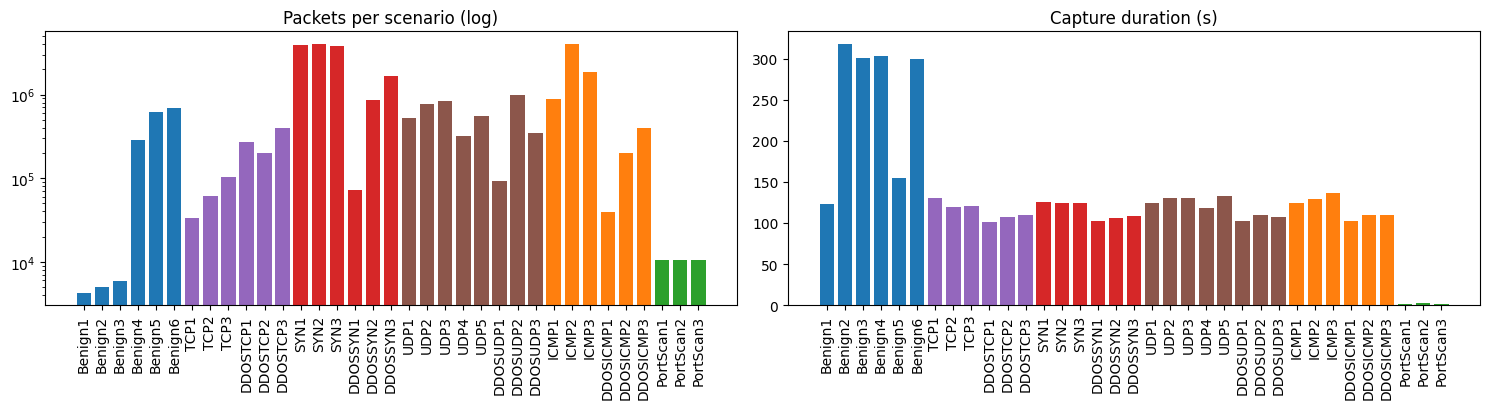

In [6]:
SS["pkts_per_s"]  = SS.rows / SS.duration_s.where(SS.duration_s > 0)
SS["dup_pct"]     = 100 * SS.exact_dup_rows / SS.rows
SS["date_utc"]    = SS.t_start_utc.dt.date
display(SS[["scenario", "family", "mode", "rows", "duration_s", "pkts_per_s", "t_start_utc", "dup_pct", "backward_steps", "max_gap_s",
            "unknown_tz_rows", "tz_labels", "n_src_ips", "top_src_ip", "top_dst_ip", "top_ttl", "top_tcp_window"]])
print(f"Total packets: {SS.rows.sum():,}   scenarios read: {len(SS)}")
SS.to_csv(f"{OUT}/scenario_statistics.csv", index=False)
if len(PS): PS.to_csv(f"{OUT}/packets_per_second.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
cols = {f: c for f, c in zip(sorted(SS.family.unique()), plt.cm.tab10.colors)}
ax[0].bar(SS.scenario, SS.rows.clip(lower=1), color=[cols[f] for f in SS.family]); ax[0].set_yscale("log"); ax[0].tick_params(axis="x", rotation=90); ax[0].set_title("Packets per scenario (log)")
ax[1].bar(SS.scenario, SS.duration_s.fillna(0), color=[cols[f] for f in SS.family]); ax[1].tick_params(axis="x", rotation=90); ax[1].set_title("Capture duration (s)")
plt.tight_layout(); plt.savefig(f"{OUT}/scenario_overview.png", dpi=110); plt.show()

## 6. Timestamps: time zones, ordering, gaps and overlap
These checks decide whether packet time can be aligned with the 1 Hz radio data: tz labels must be known, time must be monotonic, and scenarios must not overlap each other.

In [7]:
print("Time-zone labels seen:", sorted(set(l.split(":")[0] for t in SS.tz_labels for l in t.split(",") if l)))
print("Rows whose tz label is not in TZ_OFFSETS (treated as UTC!):", int(SS.unknown_tz_rows.sum()))
print("Scenarios with backward time steps :", int((SS.backward_steps > 0).sum()), "  total steps:", int(SS.backward_steps.sum()))
print("Scenarios with silent gaps >", GAP_SECONDS, "s:", int((SS.gaps_gt_threshold > 0).sum()), "  longest gap (s):", round(SS.max_gap_s.max(), 1))

T = SS.sort_values("t_start_utc")[["scenario", "family", "t_start_utc", "t_end_utc", "duration_s"]].reset_index(drop=True)
T["overlaps_previous"] = T.t_start_utc < T.t_end_utc.shift()
display(T)
print("Scenario pairs that overlap in time:", int(T.overlaps_previous.sum()))
print("\nCapture date (UTC) by family - if benign is on different days from attacks, absolute time would leak the label:")
display(pd.crosstab(SS.family, SS.date_utc))
T.to_csv(f"{OUT}/scenario_time_windows.csv", index=False)

Time-zone labels seen: ['GMT', 'IST']
Rows whose tz label is not in TZ_OFFSETS (treated as UTC!): 0
Scenarios with backward time steps : 26   total steps: 462955
Scenarios with silent gaps > 5 s: 4   longest gap (s): 39.4


,scenario,family,t_start_utc,t_end_utc,duration_s,overlaps_previous
0,PortScan1,PortScan,2025-02-27 13:39:10.057395697,2025-02-27 13:39:11.438234806,1.381,False
1,PortScan2,PortScan,2025-02-27 13:42:27.594389200,2025-02-27 13:42:30.016585349,2.422,False
2,PortScan3,PortScan,2025-02-27 13:43:52.227560043,2025-02-27 13:43:53.202548981,0.975,False
3,UDP1,UDP,2025-02-27 13:45:53.178363800,2025-02-27 13:47:56.959231615,123.781,False
4,UDP2,UDP,2025-02-27 13:49:33.097461939,2025-02-27 13:51:43.240951300,130.143,False
5,UDP3,UDP,2025-03-06 14:09:46.064028263,2025-03-06 14:11:55.893438339,129.829,False
6,UDP4,UDP,2025-03-06 14:13:13.049508095,2025-03-06 14:15:11.397863865,118.348,False
7,UDP5,UDP,2025-03-06 14:20:25.172673225,2025-03-06 14:22:37.650454998,132.478,False
8,TCP1,TCP,2025-03-06 14:37:50.545026064,2025-03-06 14:40:00.593173981,130.048,False
9,TCP2,TCP,2025-03-06 15:02:19.659896851,2025-03-06 15:04:19.656087637,119.996,False


Scenario pairs that overlap in time: 0

Capture date (UTC) by family - if benign is on different days from attacks, absolute time would leak the label:


date_utc,2025-02-27,2025-03-06,2025-04-03,2025-04-14
family,,,,
Benign,0,0,0,6
ICMP,0,3,3,0
PortScan,3,0,0,0
SYN,0,3,3,0
TCP,0,3,3,0
UDP,2,3,3,0


## 7. Packet-column quality (nulls, encapsulation, protocol stacks)

In [8]:
NP = pd.DataFrame(NULLPCT).T
display(NP[PKT_COLS].describe().T[["min", "mean", "max"]].rename(columns=lambda c: "null_% " + c))
print("TCP-only columns are NaN for UDP/ICMP packets by design (structural sparsity, not missing data).")
print("\nPackets whose ip.proto holds several comma-separated values (encapsulated / tunnelled):", int(SS.rows_with_comma_ip_proto.sum()))
ST = pd.concat(STACK, axis=1).fillna(0).sum(axis=1).sort_values(ascending=False)
print("\nTop protocol stacks (all scenarios):"); print((ST.head(15) / ST.sum() * 100).round(3).to_string())
low = ST.index.str.lower()
for tag in ["gtp", "sctp", "ngap", "pfcp", "sll", "vlan", "vssmonitoring"]:
    print(f"  stacks containing '{tag}': {int(ST[low.str.contains(tag)].sum()):,} packets")
print("\n'sll' = Linux cooked capture (capture on the 'any' interface); this is evidence about WHERE the capture was taken - it does not by itself prove the packets are post-GTP.")

,null_% min,null_% mean,null_% max
frame.time,0.000,0.000,0.000
frame.len,0.000,0.000,0.000
frame.protocols,0.000,0.000,0.000
ip.src,0.000,0.000,0.000
ip.dst,0.000,0.000,0.000
ip.proto,0.000,0.000,0.000
ip.ttl,0.000,0.000,0.000
ip.len,0.000,0.000,0.000
ip.id,0.000,0.000,0.000
ip.flags,0.000,0.000,0.000


TCP-only columns are NaN for UDP/ICMP packets by design (structural sparsity, not missing data).

Packets whose ip.proto holds several comma-separated values (encapsulated / tunnelled): 19817389

Top protocol stacks (all scenarios):
frame.protocols
sll:ethertype:ip:udp:gtp:ip:tcp         48.068
sll:ethertype:ip:icmp:data              13.015
sll:ethertype:ip:udp:gtp:ip:icmp:data   10.462
sll:ethertype:ip:udp:ntp                 6.223
sll:ethertype:ip:tcp                     5.740
sll:ethertype:ip:udp:gtp:ip:udp:ntp      4.148
sll:ethertype:ip:udp                     2.832
sll:ethertype:ip:udp:gtp:ip:udp          2.235
sll:ethertype:ip:udp:gtp:ip:icmp         2.203
sll:ethertype:ip:tcp:data                2.005
sll:ethertype:ip:udp:gtp:ip:tcp:data     1.640
sll:ethertype:ip:tcp:vssmonitoring       1.188
sll:ethertype:ip:udp:data                0.168
sll:ethertype:ip:tcp:ssh                 0.026
sll:ethertype:ip:udp:gtp:ip:udp:data     0.016
  stacks containing 'gtp': 19,815,160 packets


## 8. Class distribution (three levels)
Scenario counts, packets and **seconds**. Packets are dominated by floods; seconds are the unit that will actually be joined to the radio data, so they are what the class balance should be judged on.

,is_attack,family,mode,scenarios,packets,seconds,pct_packets,pct_seconds
0,0,Benign,Benign,6,1606805,1201,5.578,28.232
1,1,ICMP,DDoS,3,634548,324,2.203,7.616
2,1,ICMP,DoS,3,6764757,372,23.486,8.745
3,1,PortScan,PortScan,3,31465,8,0.109,0.188
4,1,SYN,DDoS,3,2609555,320,9.060,7.522
5,1,SYN,DoS,3,11661285,376,40.485,8.839
6,1,TCP,DDoS,3,867026,321,3.010,7.546
7,1,TCP,DoS,3,198876,373,0.690,8.768
8,1,UDP,DDoS,3,1441650,322,5.005,7.569
9,1,UDP,DoS,5,2988005,637,10.374,14.974


,scenarios,packets,seconds
is_attack,,,
0,6,1606805,1201
1,29,27197167,3053


Attack:benign ratio -> scenarios 29:6   packets 16.9:1   seconds 2.5:1


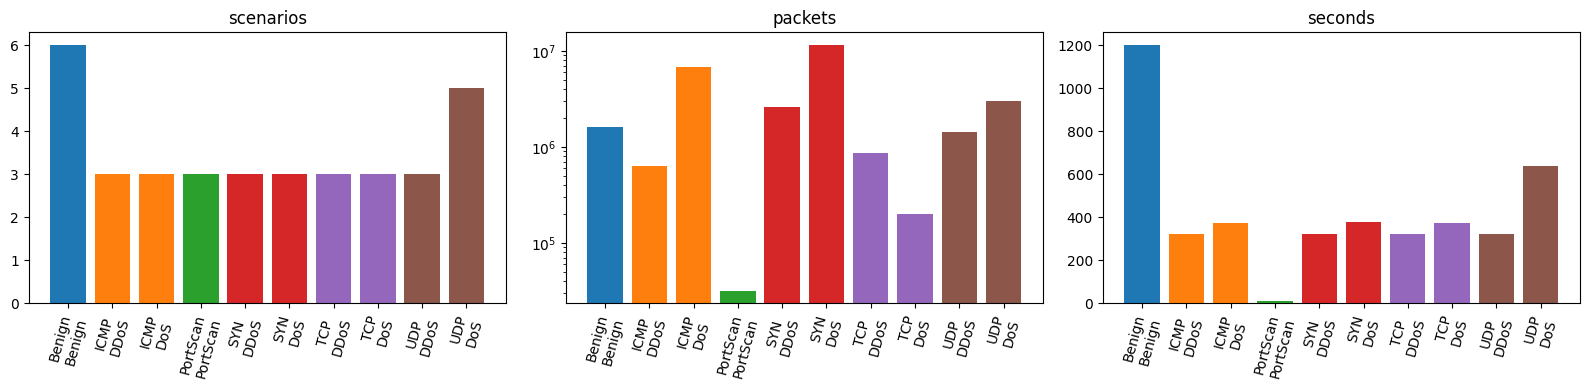

In [9]:
sec_counts = PS.groupby("scenario").size().rename("seconds") if len(PS) else pd.Series(dtype=int, name="seconds")
CD = SS.merge(sec_counts, on="scenario", how="left")
fam = CD.groupby(["is_attack", "family", "mode"]).agg(scenarios=("scenario", "count"), packets=("rows", "sum"), seconds=("seconds", "sum")).reset_index()
fam["pct_packets"] = 100 * fam.packets / fam.packets.sum(); fam["pct_seconds"] = 100 * fam.seconds / fam.seconds.sum()
display(fam)
bin_ = CD.groupby("is_attack").agg(scenarios=("scenario", "count"), packets=("rows", "sum"), seconds=("seconds", "sum"))
display(bin_)
b, a = bin_.reindex([0, 1]).fillna(0).values
print(f"Attack:benign ratio -> scenarios {a[0]:.0f}:{b[0]:.0f}   packets {a[1]/max(b[1],1):.1f}:1   seconds {a[2]/max(b[2],1):.1f}:1")
fam.to_csv(f"{OUT}/class_distribution.csv", index=False)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
lab = (fam.family + "\n" + fam["mode"])
for k, c in enumerate(["scenarios", "packets", "seconds"]):
    ax[k].bar(lab, fam[c], color=[cols[f] for f in fam.family]); ax[k].set_title(c); ax[k].tick_params(axis="x", rotation=75)
    if c == "packets": ax[k].set_yscale("log")
plt.tight_layout(); plt.savefig(f"{OUT}/class_distribution.png", dpi=110); plt.show()

## 9. Traffic behaviour over time (1-second windows)
This is the view that matters for alignment: what each attack looks like second by second, and when it starts.

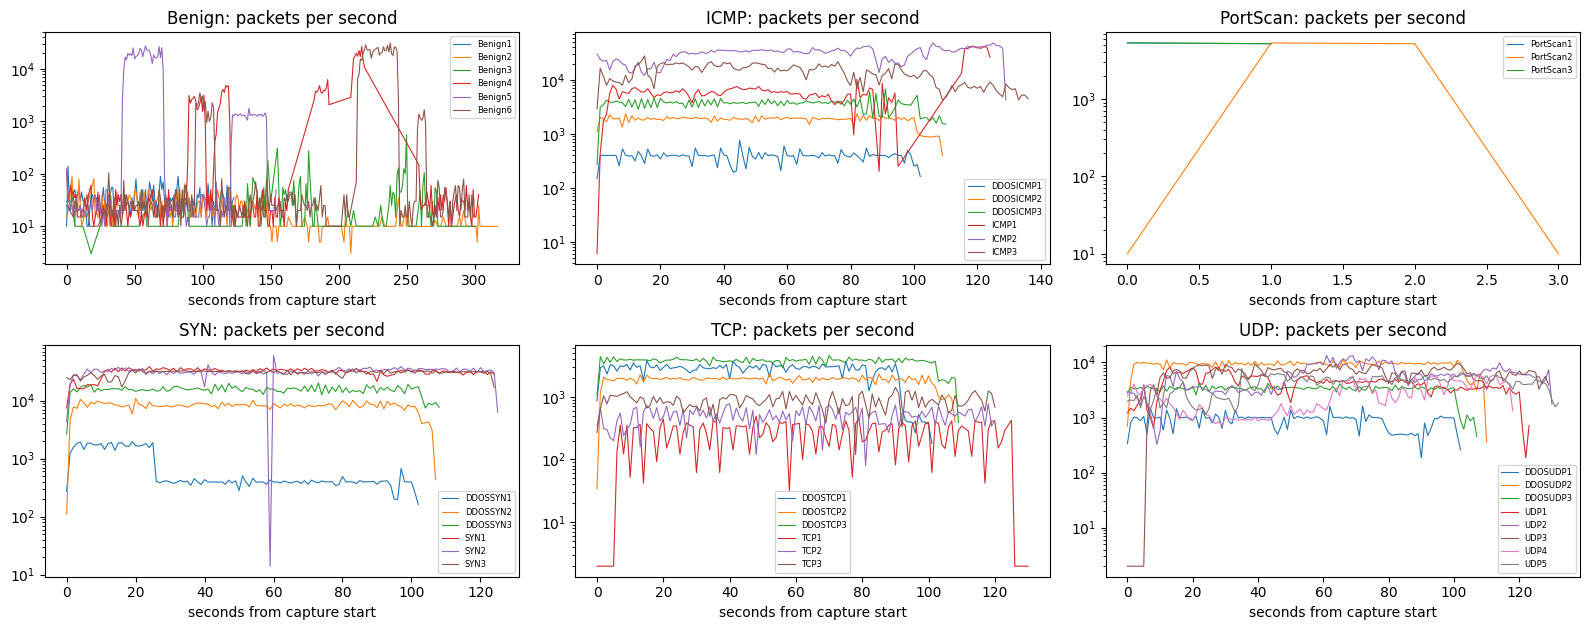

,scenario,seconds_with_traffic,span_s,idle_seconds,p50_pps,p95_pps,max_pps,first_second_over_5x_start,family,mode
0,Benign1,124,124,0,30.000,64.250,140,NaN,Benign,Benign
1,Benign2,237,318,81,10.000,45.000,90,4.000,Benign,Benign
2,Benign3,180,302,122,10.000,74.750,560,0.000,Benign,Benign
3,Benign4,232,304,72,20.000,"4,336.100",26953,89.000,Benign,Benign
4,Benign5,155,155,0,30.000,"22,432.700",27501,0.000,Benign,Benign
5,Benign6,273,300,27,25.000,"22,427.450",31558,0.000,Benign,Benign
6,DDOSICMP1,103,103,0,394.000,540.600,756,NaN,ICMP,DDoS
7,DDOSICMP2,110,110,0,"1,907.000","2,161.100",2360,NaN,ICMP,DDoS
8,DDOSICMP3,111,111,0,"3,726.000","4,541.000",6800,NaN,ICMP,DDoS
9,DDOSSYN1,103,103,0,400.000,"1,857.600",1957,NaN,SYN,DDoS


idle_seconds > 0 means seconds with NO packets: those windows would be missing in a per-second join unless filled with zeros.


In [10]:
if len(PS):
    PS = PS.merge(SS[["scenario", "family", "mode", "is_attack"]], on="scenario")
    PS["t_rel"] = PS.epoch_s - PS.groupby("scenario").epoch_s.transform("min")
    PS["mean_len"] = PS.bytes / PS.pkts
    PS["syn_frac"], PS["udp_frac"], PS["icmp_frac"] = PS.syn / PS.pkts, PS.udp / PS.pkts, PS.icmp / PS.pkts
    fams = sorted(PS.family.unique()); nc = 3; nr = int(np.ceil(len(fams) / nc))
    fig, axes = plt.subplots(nr, nc, figsize=(16, 3.2 * nr)); axes = np.atleast_1d(axes).ravel()
    for ax, f in zip(axes, fams):
        for sc, g in PS[PS.family == f].groupby("scenario"): ax.plot(g.t_rel, g.pkts, lw=.8, label=sc)
        ax.set_yscale("log"); ax.set_title(f"{f}: packets per second"); ax.set_xlabel("seconds from capture start"); ax.legend(fontsize=6)
    for ax in axes[len(fams):]: ax.axis("off")
    plt.tight_layout(); plt.savefig(f"{OUT}/packets_per_second_by_family.png", dpi=110); plt.show()

    rows = []
    for sc, g in PS.groupby("scenario"):
        full = g.set_index("t_rel").pkts.reindex(np.arange(0, int(g.t_rel.max()) + 1), fill_value=0)
        base = max(full.iloc[: max(5, len(full) // 10)].median(), 1)
        over = np.where(full.values > 5 * base)[0]
        rows.append({"scenario": sc, "seconds_with_traffic": int((full > 0).sum()), "span_s": len(full), "idle_seconds": int((full == 0).sum()),
                     "p50_pps": full.median(), "p95_pps": full.quantile(.95), "max_pps": full.max(), "first_second_over_5x_start": int(over[0]) if len(over) else None})
    DYN = pd.DataFrame(rows).merge(SS[["scenario", "family", "mode"]], on="scenario"); display(DYN)
    DYN.to_csv(f"{OUT}/scenario_dynamics.csv", index=False)
    print("idle_seconds > 0 means seconds with NO packets: those windows would be missing in a per-second join unless filled with zeros.")
else:
    print("No per-second data (no packets read).")

## 10. Leakage investigation - computed, not asserted
Every statement below is produced from the data read above. A risk is only reported as present when the table shows it.

In [11]:
def ip_table(counters, role):
    rows = []
    for sc, s in counters.items():
        for ip, n in s[s > 0].items(): rows.append((role, ip, sc, int(n)))
    return pd.DataFrame(rows, columns=["role", "ip", "scenario", "pkts"])
IPT = pd.concat([ip_table(IPSRC, "src"), ip_table(IPDST, "dst")]).merge(SS[["scenario", "family", "is_attack"]], on="scenario")
ex = IPT.groupby(["role", "ip"]).agg(scenarios=("scenario", "nunique"), pkts=("pkts", "sum"), attack_pkts=("pkts", lambda s: s[IPT.loc[s.index, "is_attack"] == 1].sum()),
                                     families=("family", lambda s: ",".join(sorted(set(s))))).reset_index()
ex["attack_share"] = ex.attack_pkts / ex.pkts
ex["exclusive_to"] = np.select([ex.attack_share == 1, ex.attack_share == 0], ["attack only", "benign only"], "both")
display(ex.sort_values("pkts", ascending=False).head(25))
for role in ["src", "dst"]:
    e = ex[ex.role == role]; tot = e.pkts.sum()
    print(f"{role}: {len(e)} distinct IPs; packets from IPs seen ONLY in attack scenarios: {100*e[e.exclusive_to=='attack only'].pkts.sum()/tot:.1f}%   "
          f"only in benign: {100*e[e.exclusive_to=='benign only'].pkts.sum()/tot:.1f}%   in both: {100*e[e.exclusive_to=='both'].pkts.sum()/tot:.1f}%")
ex.to_csv(f"{OUT}/leakage_ip_table.csv", index=False)

print("\ntcp.stream range per capture (does it restart in every file?):")
tsr = SS[["scenario", "tcp_stream_min", "tcp_stream_max"]]; display(tsr.T)
print("captures where tcp.stream starts at 0:", int((SS.tcp_stream_min == 0).sum()), "of", int(SS.tcp_stream_min.notna().sum()))

print("\nTool/OS fingerprints (most common TTL and TCP window per scenario):")
display(SS[["scenario", "family", "top_ttl", "top_tcp_window", "mean_frame_len"]])
fp = SS.groupby("family").top_ttl.nunique(); print("distinct top-TTL values per family:", fp.to_dict())

,role,ip,scenarios,pkts,attack_pkts,families,attack_share,exclusive_to
8,dst,"172.31.0.134,192.168.0.10",35,17275306,17223516,"Benign,ICMP,PortScan,SYN,TCP,UDP",0.997,both
27,src,"172.31.0.1,172.16.0.4",13,14141889,14141533,"Benign,ICMP,SYN,TCP,UDP",1.000,both
13,dst,192.168.0.10,27,5699594,5511498,"Benign,ICMP,PortScan,SYN,TCP,UDP",0.967,both
30,src,172.31.0.134,27,3799390,3673993,"Benign,ICMP,PortScan,SYN,TCP,UDP",0.967,both
35,src,192.168.0.10,24,3286989,2426567,"Benign,ICMP,PortScan,SYN,TCP,UDP",0.738,both
31,src,"172.31.0.134,192.168.0.10",24,2539854,2033357,"Benign,ICMP,PortScan,SYN,TCP,UDP",0.801,both
7,dst,172.31.0.134,24,2034642,1461072,"Benign,ICMP,PortScan,SYN,TCP,UDP",0.718,both
33,src,192.168.0.1,27,1900192,1837493,"Benign,ICMP,PortScan,SYN,TCP,UDP",0.967,both
5,dst,"172.31.0.1,172.16.0.4",10,1289891,1288958,"Benign,ICMP,TCP,UDP",0.999,both
11,dst,192.168.0.1,24,1252347,965495,"Benign,ICMP,PortScan,SYN,TCP,UDP",0.771,both


src: 22 distinct IPs; packets from IPs seen ONLY in attack scenarios: 8.9%   only in benign: 0.2%   in both: 91.0%
dst: 16 distinct IPs; packets from IPs seen ONLY in attack scenarios: 2.6%   only in benign: 1.8%   in both: 95.7%

tcp.stream range per capture (does it restart in every file?):


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34
scenario,Benign1,Benign2,Benign3,Benign4,Benign5,Benign6,TCP1,TCP2,TCP3,DDOSTCP1,DDOSTCP2,DDOSTCP3,SYN1,SYN2,SYN3,DDOSSYN1,DDOSSYN2,DDOSSYN3,UDP1,UDP2,UDP3,UDP4,UDP5,DDOSUDP1,DDOSUDP2,DDOSUDP3,ICMP1,ICMP2,ICMP3,DDOSICMP1,DDOSICMP2,DDOSICMP3,PortScan1,PortScan2,PortScan3
tcp_stream_min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000,0.000,0.000
tcp_stream_max,5.000,5.000,7.000,29.000,14.000,20.000,"10,058.000","18,131.000","31,394.000",5.000,1.000,1.000,"32,767.000","32,772.000","32,767.000",3.000,5.000,5.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000,8.000,5.000


captures where tcp.stream starts at 0: 21 of 21

Tool/OS fingerprints (most common TTL and TCP window per scenario):


,scenario,family,top_ttl,top_tcp_window,mean_frame_len
0,Benign1,Benign,64,501,146.265
1,Benign2,Benign,64,501,173.943
2,Benign3,Benign,64,501,172.515
3,Benign4,Benign,64,509,"1,617.936"
4,Benign5,Benign,64,509,"1,907.421"
5,Benign6,Benign,64,509,"2,012.072"
6,TCP1,TCP,64,0,84.320
7,TCP2,TCP,64,0,84.200
8,TCP3,TCP,64,0,84.200
9,DDOSTCP1,TCP,63,0,83.842


distinct top-TTL values per family: {'Benign': 1, 'ICMP': 1, 'PortScan': 1, 'SYN': 1, 'TCP': 2, 'UDP': 2}


## 11. How separable are scenarios from simple per-second features?
This replaces the old "first 5,000 rows per scenario, random 5-fold" test, which mostly measured neighbouring packets of the same scenario.
Features are per-second traffic statistics only (no IPs, no time). Two evaluations are compared: **random folds** and **scenario-held-out folds**. A large gap is evidence that random splits are over-optimistic.

In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_val_predict
from sklearn.metrics import f1_score, balanced_accuracy_score
FEATS = ["pkts", "bytes", "mean_len", "tcp", "udp", "icmp", "syn", "synack", "rst", "n_src", "n_dst", "n_dport"]
D = PS.dropna(subset=FEATS + ["family"]).copy() if len(PS) else pd.DataFrame()
if len(D) > 200 and D.family.nunique() > 1:
    D = D.assign(_r=np.random.RandomState(RANDOM_STATE).rand(len(D))); D = D[D.groupby("scenario")._r.rank() <= 400].drop(columns="_r")   # equal weight per scenario
    X, yfam, ybin, grp = D[FEATS].astype(float), D.family.values, D.is_attack.values, D.scenario.values
    rf = RandomForestClassifier(n_estimators=100, max_depth=10, n_jobs=-1, class_weight="balanced_subsample", random_state=RANDOM_STATE)
    ng = D.scenario.nunique(); res = []
    for name, cv, kw in [("random folds", StratifiedKFold(5, shuffle=True, random_state=0), {}), ("scenario-held-out folds", GroupKFold(min(5, ng)), {"groups": grp})]:
        pf = cross_val_predict(rf, X, yfam, cv=cv, **kw); pb = cross_val_predict(rf, X, ybin, cv=cv, **kw)
        res.append({"evaluation": name, "family macro-F1": f1_score(yfam, pf, average="macro"), "attack-vs-benign balanced acc": balanced_accuracy_score(ybin, pb)})
    R = pd.DataFrame(res); display(R)
    print("rows used:", len(D), " scenarios:", ng, " benign scenarios with seconds:", D[D.is_attack == 0].scenario.nunique())
    print("The gap between the two rows is the optimism of a random split; report the scenario-held-out figure.")
    R.to_csv(f"{OUT}/scenario_predictability.csv", index=False)
else:
    print("Not enough per-second data for this check.")

,evaluation,family macro-F1,attack-vs-benign balanced acc
0,random folds,0.996,0.999
1,scenario-held-out folds,0.888,0.998


rows used: 4254  scenarios: 35  benign scenarios with seconds: 6
The gap between the two rows is the optimism of a random split; report the scenario-held-out figure.


## 12. Flow files and cross-check with the flow database

In [13]:
def count_lines(path):
    n = 0
    with open(path, "rb") as fh:
        for blk in iter(lambda: fh.read(1 << 22), b""): n += blk.count(b"\n")
    return max(n - 1, 0)
fl = MAN[MAN.flow_path.notna()][["scenario", "family", "flow_path"]].copy()
fl["flow_rows"] = fl.flow_path.map(count_lines)
fl = fl.merge(SS[["scenario", "rows"]].rename(columns={"rows": "packets"}), on="scenario", how="left"); fl["packets_per_flow"] = fl.packets / fl.flow_rows.where(fl.flow_rows > 0)
display(fl.drop(columns="flow_path"))
print(f"flow rows over all scenario files: {fl.flow_rows.sum():,}")
heads = {s: tuple(pd.read_csv(p, nrows=0).columns) for s, p in zip(fl.scenario, fl.flow_path)}
print("flow schema identical in every file:", len(set(heads.values())) == 1, "-", list(next(iter(heads.values()))) if heads else "")
fdb = DBINFO[(DBINFO.kind == "FLOWS")] if len(DBINFO) else pd.DataFrame()
if len(fdb): print(f"flow database rows: {int(fdb.rows.iloc[0]):,}  ->  equals sum of flow files: {int(fdb.rows.iloc[0]) == int(fl.flow_rows.sum())}")
print("\nScenarios with <= 12 flow rows cannot be characterised at flow level; use packet windows for them:")
print(fl[fl.flow_rows <= 12][["scenario", "flow_rows", "packets"]].to_string(index=False))
fl.drop(columns="flow_path").to_csv(f"{OUT}/flow_vs_packet_counts.csv", index=False)

,scenario,family,flow_rows,packets,packets_per_flow
0,Benign1,Benign,7,4270,610.000
1,Benign2,Benign,12,5035,419.583
2,Benign3,Benign,11,5899,536.273
3,Benign4,Benign,26,288066,"11,079.462"
4,Benign5,Benign,15,613865,"40,924.333"
5,Benign6,Benign,21,689670,"32,841.429"
6,TCP1,TCP,6709,33786,5.036
7,TCP2,TCP,12090,60440,4.999
8,TCP3,TCP,20933,104650,4.999
9,DDOSTCP1,TCP,76,267026,"3,513.500"


flow rows over all scenario files: 204,775
flow schema identical in every file: True - ['src_ip', 'dst_ip', 'proto', 'service', 'duration', 'orig_bytes', 'resp_bytes', 'conn_state', 'orig_pkts', 'resp_pkts', 'orig_ip_bytes', 'resp_ip_bytes', 'history']
flow database rows: 204,775  ->  equals sum of flow files: True

Scenarios with <= 12 flow rows cannot be characterised at flow level; use packet windows for them:
 scenario  flow_rows  packets
  Benign1          7     4270
  Benign2         12     5035
  Benign3         11     5899
 DDOSTCP2          2   200000
 DDOSTCP3          2   400000
     SYN1          3  3902664
     SYN2          3  3981760
     SYN3          3  3776861
     UDP1          6   527653
     UDP2          5   768866
     UDP3          6   827979
     UDP4          5   316698
     UDP5         12   546809
 DDOSUDP1          8    91650
 DDOSUDP2          6  1000000
 DDOSUDP3          4   350000
    ICMP1          5   876078
    ICMP2          5  4045321
    ICMP3    

## 13. Limitations - each status is computed from the evidence above

In [14]:
def status(cond, evidence): return ("CONFIRMED" if cond else "NOT OBSERVED"), evidence
L = []
benign_ok = SS[(SS.is_attack == 0) & (SS.rows > 1000)].scenario.tolist()
L.append(("Packet DB with labels is not shipped / Higher_Layer db holds flows", *status(not HAS_PACKET_DB, f"db inspection: kinds = {sorted(set(DBINFO.kind)) if len(DBINFO) else 'no db found'}")))
L.append(("Few benign scenarios have meaningful packet counts", *status(len(benign_ok) < 6, f"benign scenarios with >1000 packets: {benign_ok}")))
L.append(("Class imbalance in packets", *status(bin_.reindex([0, 1]).fillna(0).packets.values[0] * 10 < bin_.reindex([0, 1]).fillna(0).packets.values[1], f"attack:benign packets = {a[1]/max(b[1],1):.1f}:1")))
L.append(("Unknown time-zone labels present", *status(SS.unknown_tz_rows.sum() > 0, f"rows with unknown tz label: {int(SS.unknown_tz_rows.sum())}")))
L.append(("Timestamps not monotonic inside captures", *status(SS.backward_steps.sum() > 0, f"backward steps: {int(SS.backward_steps.sum())}")))
L.append(("Silent gaps inside captures", *status((SS.gaps_gt_threshold > 0).any(), f"scenarios with gaps: {int((SS.gaps_gt_threshold > 0).sum())}, longest {SS.max_gap_s.max():.1f}s")))
L.append(("Scenarios overlap in time", *status(T.overlaps_previous.any(), f"overlapping pairs: {int(T.overlaps_previous.sum())}")))
L.append(("Exact duplicate packets", *status((SS.dup_pct > 0.5).any(), f"max duplicate share: {SS.dup_pct.max():.2f}%")))
src_ex = ex[ex.role == "src"]; share_att_only = src_ex[src_ex.exclusive_to == "attack only"].pkts.sum() / src_ex.pkts.sum()
L.append(("Source IP reveals the class", *status(share_att_only > 0.5, f"{100*share_att_only:.1f}% of packets come from IPs that only occur in attack scenarios")))
L.append(("tcp.stream restarts per capture (scenario identifier)", *status((SS.tcp_stream_min == 0).sum() > 1, f"{int((SS.tcp_stream_min == 0).sum())} captures start at stream 0")))
L.append(("Encapsulation (GTP/SCTP) visible", *status(bool(low.str.contains("gtp|sctp").any()), "searched all protocol stacks")))
L.append(("Tunnelled / multi-valued header fields", *status(SS.rows_with_comma_ip_proto.sum() > 0, f"rows with comma-separated ip.proto: {int(SS.rows_with_comma_ip_proto.sum())}")))
LIM = pd.DataFrame(L, columns=["limitation", "status", "evidence"]); display(LIM)
LIM.to_csv(f"{OUT}/limitations.csv", index=False)
summary = {"packets_total": int(SS.rows.sum()), "scenarios": int(len(SS)), "outputs_dir": OUT, "limitations": LIM.to_dict("records")}
json.dump(summary, open(f"{OUT}/network_analysis_summary.json", "w"), indent=2, default=str)
print("\nSaved all tables/figures to", OUT)

,limitation,status,evidence
0,Packet DB with labels is not shipped / Higher_...,CONFIRMED,db inspection: kinds = ['FLOWS']
1,Few benign scenarios have meaningful packet co...,NOT OBSERVED,benign scenarios with >1000 packets: ['Benign1...
2,Class imbalance in packets,CONFIRMED,attack:benign packets = 16.9:1
3,Unknown time-zone labels present,NOT OBSERVED,rows with unknown tz label: 0
4,Timestamps not monotonic inside captures,CONFIRMED,backward steps: 462955
5,Silent gaps inside captures,CONFIRMED,"scenarios with gaps: 4, longest 39.4s"
6,Scenarios overlap in time,NOT OBSERVED,overlapping pairs: 0
7,Exact duplicate packets,CONFIRMED,max duplicate share: 20.06%
8,Source IP reveals the class,NOT OBSERVED,8.9% of packets come from IPs that only occur ...
9,tcp.stream restarts per capture (scenario iden...,CONFIRMED,21 captures start at stream 0



Saved all tables/figures to /kaggle/working/analysis/network_outputs
